In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Dataset directory
DATA_PATH = Path("../csv_source_files")

# Load livestock datasets
livestock_population_df = pd.read_csv(
    DATA_PATH / "07_livestock_population_yearly.csv"
)

livestock_products_df = pd.read_csv(
    DATA_PATH / "08_livestock_products_yearly.csv"
)

print("Livestock datasets loaded successfully!")

Livestock datasets loaded successfully!


### Livestock Population

In [ ]:
print("LIVESTOCK POPULATION")
print("Shape:", livestock_population_df.shape)
display(livestock_population_df.head())
print("\nColumns:", livestock_population_df.columns.tolist())


LIVESTOCK POPULATION
Shape: (110, 3)


,Fiscal_Year,Category,Population
0,2024/25,Cattle,5141391
1,2024/25,Buffaloes,3294723
2,2024/25,Sheep,652742
3,2024/25,Goat,15954080
4,2024/25,Pigs,1480832



Columns: ['Fiscal_Year', 'Category', 'Population']

LIVESTOCK PRODUCTS
Shape: (150, 3)


,Fiscal_Year,Product,Value
0,2024/25,Milk Production (Mt.),2718177.0
1,2024/25,Cow Milk (Mt.),1302094.0
2,2024/25,Buff. Milk (Mt.),1416083.0
3,2024/25,Meat (Net) Production (Mt.),456430.0
4,2024/25,Buff (Mt.),141649.0



Columns: ['Fiscal_Year', 'Product', 'Value']


In [25]:
# Available livestock categories
print("LIVESTOCK CATEGORIES")
print(livestock_population_df["Category"].unique())

# Available fiscal years
print("\nFISCAL YEARS")
print(sorted(livestock_population_df["Fiscal_Year"].unique()))

# Records per fiscal year
print("\nPOPULATION RECORDS PER YEAR")
display(livestock_population_df.groupby("Fiscal_Year").size())


LIVESTOCK CATEGORIES
<StringArray>
[           'Cattle',         'Buffaloes',             'Sheep',
              'Goat',              'Pigs',              'Fowl',
              'Duck',       'Milking Cow', 'Milking Buffaloes',
        'Laying Hen',       'Laying Duck']
Length: 11, dtype: str

FISCAL YEARS
['2015/16', '2016/17', '2017/18', '2018/19', '2019/20', '2020/21', '2021/22', '2022/23', '2023/24', '2024/25']

POPULATION RECORDS PER YEAR


Fiscal_Year
2015/16    11
2016/17    11
2017/18    11
2018/19    11
2019/20    11
2020/21    11
2021/22    11
2022/23    11
2023/24    11
2024/25    11
dtype: int64

In [20]:
# Main livestock population categories
main_livestock = [
    "Cattle",
    "Buffaloes",
    "Sheep",
    "Goat",
    "Pigs",
    "Fowl",
    "Duck"
]

livestock_main_df = livestock_population_df[
    livestock_population_df["Category"].isin(main_livestock)
].copy()

# Population by category across fiscal years
population_pivot = livestock_main_df.pivot(
    index="Fiscal_Year",
    columns="Category",
    values="Population"
)

display(population_pivot)

Category,Buffaloes,Cattle,Duck,Fowl,Goat,Pigs,Sheep
Fiscal_Year,,,,,,,
2015/16,5168809,7302808,392255,68630638,10986114,1291308,800658
2016/17,5177998,7347487,394775,70007151,11165099,1328036,801975
2017/18,5277819,7376306,404670,72245732,11647319,1435369,800749
2018/19,5308664,7385035,416400,75709330,12283752,1488338,798889
2019/20,5257591,7458885,427226,82598879,12811953,1519593,806079
2020/21,5159931,7466841,432226,73418077,13442614,1588838,793725
2021/22,5132931,7413196,605943,66803116,13990703,1504623,771204
2022/23,3081061,4750329,1325998,65205250,14541244,1357507,501848
2023/24,3307031,5198388,796758,56916567,15289954,1497411,633222


In [19]:
# Total population across all 10 years by category
population_contribution = (
    livestock_main_df.groupby("Category")["Population"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

# Calculate percentage contribution
population_contribution["Contribution_%"] = (
    population_contribution["Population"]
    / population_contribution["Population"].sum()
) * 100

display(population_contribution)

,Category,Population,Contribution_%
0,Fowl,687926420,71.589805
1,Goat,132112832,13.748464
2,Cattle,66840666,6.955846
3,Buffaloes,46166558,4.804373
4,Pigs,14491855,1.508111
5,Sheep,7361091,0.766040
6,Duck,6028486,0.627361


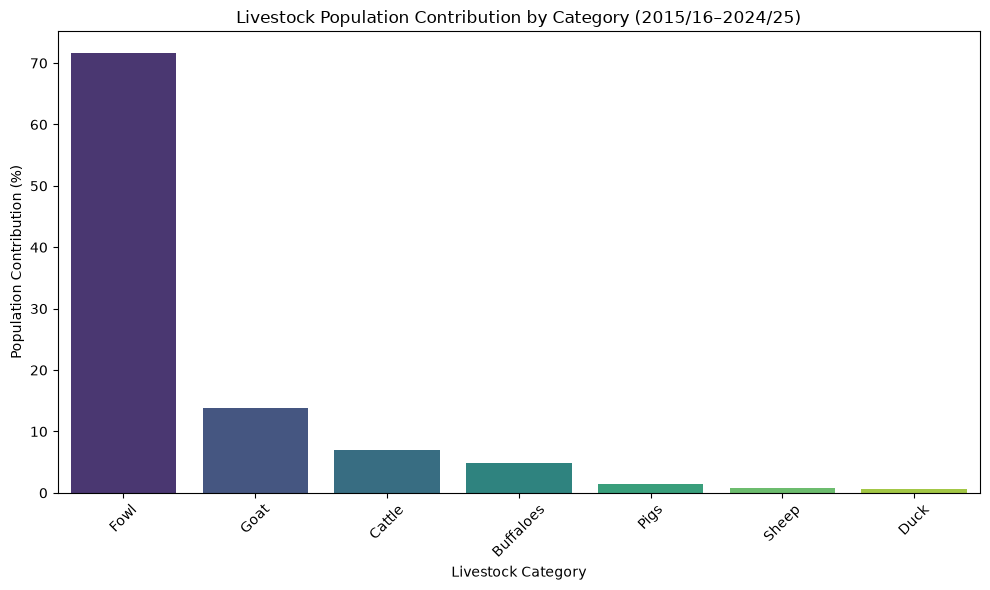

In [21]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=population_contribution,
    x="Category",
    y="Contribution_%",
    hue="Category",
    palette="viridis",
    legend=False
)

plt.title("Livestock Population Contribution by Category (2015/16–2024/25)")
plt.xlabel("Livestock Category")
plt.ylabel("Population Contribution (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

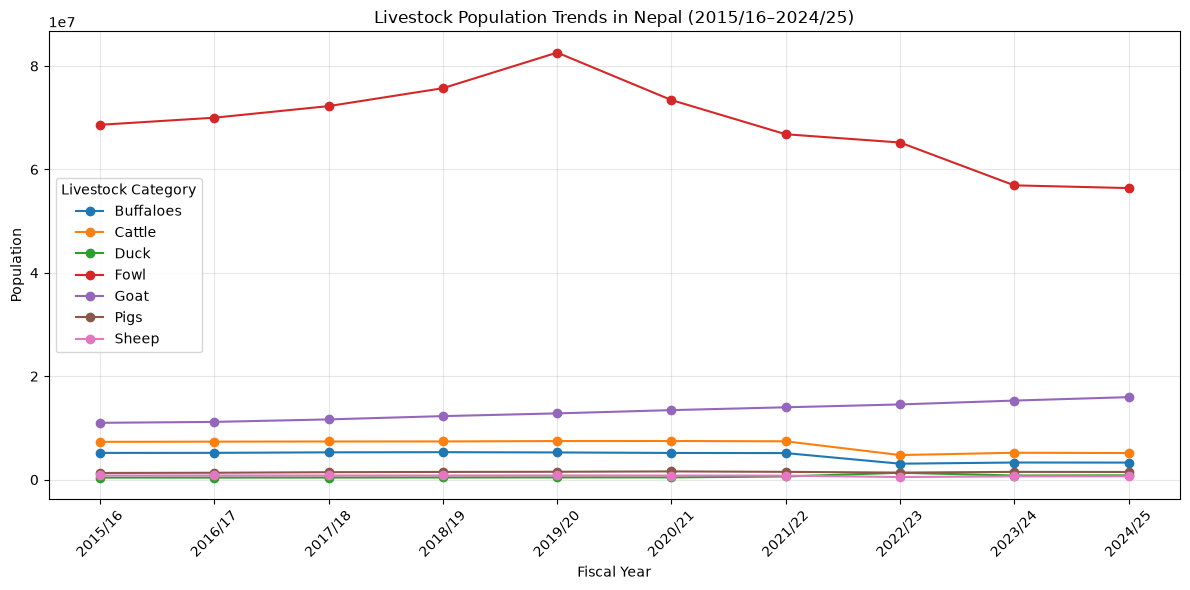

In [22]:
plt.figure(figsize=(12, 6))

for category in population_pivot.columns:
    plt.plot(
        population_pivot.index,
        population_pivot[category],
        marker="o",
        label=category
    )

plt.title("Livestock Population Trends in Nepal (2015/16–2024/25)")
plt.xlabel("Fiscal Year")
plt.ylabel("Population")
plt.xticks(rotation=45)
plt.legend(title="Livestock Category")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [27]:
population_change = pd.DataFrame({
    "Initial_Population": population_pivot.iloc[0],
    "Final_Population": population_pivot.iloc[-1]
})

population_change["Absolute_Change"] = (
    population_change["Final_Population"]
    - population_change["Initial_Population"]
)

population_change["Growth_%"] = (
    population_change["Absolute_Change"]
    / population_change["Initial_Population"]
) * 100

display(population_change.sort_values("Growth_%", ascending=False).round(2))

,Initial_Population,Final_Population,Absolute_Change,Growth_%
Category,,,,
Duck,392255,832235,439980,112.17
Goat,10986114,15954080,4967966,45.22
Pigs,1291308,1480832,189524,14.68
Fowl,68630638,56391680,-12238958,-17.83
Sheep,800658,652742,-147916,-18.47
Cattle,7302808,5141391,-2161417,-29.60
Buffaloes,5168809,3294723,-1874086,-36.26


In [26]:
# Calculate year-over-year percentage change
population_growth = population_pivot.pct_change() * 100

display(population_growth.round(2))

Category,Buffaloes,Cattle,Duck,Fowl,Goat,Pigs,Sheep
Fiscal_Year,,,,,,,
2015/16,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2016/17,0.18,0.61,0.64,2.01,1.63,2.84,0.16
2017/18,1.93,0.39,2.51,3.20,4.32,8.08,-0.15
2018/19,0.58,0.12,2.90,4.79,5.46,3.69,-0.23
2019/20,-0.96,1.00,2.60,9.10,4.30,2.10,0.90
2020/21,-1.86,0.11,1.17,-11.11,4.92,4.56,-1.53
2021/22,-0.52,-0.72,40.19,-9.01,4.08,-5.30,-2.84
2022/23,-39.97,-35.92,118.83,-2.39,3.94,-9.78,-34.93
2023/24,7.33,9.43,-39.91,-12.71,5.15,10.31,26.18


In [28]:
productive_categories = [
    "Milking Cow",
    "Milking Buffaloes",
    "Laying Hen",
    "Laying Duck"
]

productive_livestock_df = livestock_population_df[
    livestock_population_df["Category"].isin(productive_categories)
].copy()

productive_pivot = productive_livestock_df.pivot(
    index="Fiscal_Year",
    columns="Category",
    values="Population"
)

display(productive_pivot)

Category,Laying Duck,Laying Hen,Milking Buffaloes,Milking Cow
Fiscal_Year,,,,
2015/16,180927,12353515,1355384,1026135
2016/17,183940,12388889,1509512,1029529
2017/18,186912,12517558,1535948,1039538
2018/19,190747,12526979,1560584,1078775
2019/20,191701,12927842,1635492,1166156
2020/21,220531,11374011,1630642,1209040
2021/22,302472,10131642,1666827,1223061
2022/23,661937,12725053,851272,916578
2023/24,444292,13487122,1251323,1063189


In [29]:
productive_growth = productive_pivot.pct_change() * 100

display(productive_growth.round(2))

Category,Laying Duck,Laying Hen,Milking Buffaloes,Milking Cow
Fiscal_Year,,,,
2015/16,NaN,NaN,NaN,NaN
2016/17,1.67,0.29,11.37,0.33
2017/18,1.62,1.04,1.75,0.97
2018/19,2.05,0.08,1.60,3.77
2019/20,0.50,3.20,4.80,8.10
2020/21,15.04,-12.02,-0.30,3.68
2021/22,37.16,-10.92,2.22,1.16
2022/23,118.84,25.60,-48.93,-25.06
2023/24,-32.88,5.99,46.99,16.00


In [30]:
productive_change = pd.DataFrame({
    "Initial_Population": productive_pivot.iloc[0],
    "Final_Population": productive_pivot.iloc[-1]
})

productive_change["Absolute_Change"] = (
    productive_change["Final_Population"]
    - productive_change["Initial_Population"]
)

productive_change["Growth_%"] = (
    productive_change["Absolute_Change"]
    / productive_change["Initial_Population"]
) * 100

display(
    productive_change.sort_values(
        "Growth_%", ascending=False
    ).round(2)
)

,Initial_Population,Final_Population,Absolute_Change,Growth_%
Category,,,,
Laying Duck,180927,321908,140981,77.92
Milking Cow,1026135,1055828,29693,2.89
Laying Hen,12353515,12405021,51506,0.42
Milking Buffaloes,1355384,965920,-389464,-28.73


### Livestock Products

In [23]:

print("\nLIVESTOCK PRODUCTS")
print("Shape:", livestock_products_df.shape)
display(livestock_products_df.head())
print("\nColumns:", livestock_products_df.columns.tolist())


LIVESTOCK PRODUCTS
Shape: (150, 3)


,Fiscal_Year,Product,Value
0,2024/25,Milk Production (Mt.),2718177.0
1,2024/25,Cow Milk (Mt.),1302094.0
2,2024/25,Buff. Milk (Mt.),1416083.0
3,2024/25,Meat (Net) Production (Mt.),456430.0
4,2024/25,Buff (Mt.),141649.0



Columns: ['Fiscal_Year', 'Product', 'Value']


In [24]:
# Available livestock products
print("\nLIVESTOCK PRODUCTS")
print(livestock_products_df["Product"].unique())

print("\nPRODUCT RECORDS PER YEAR")
display(livestock_products_df.groupby("Fiscal_Year").size())


LIVESTOCK PRODUCTS
<StringArray>
[       'Milk Production (Mt.)',               'Cow Milk (Mt.)',
             'Buff. Milk (Mt.)',  'Meat (Net) Production (Mt.)',
                   'Buff (Mt.)',         'Mutton (Sheep) (Mt.)',
                 'Chevon (Mt.)',                   'Pork (Mt.)',
                'Chicken (Mt.)',                   'Duck (Mt.)',
 'Egg Production (‘000 Number)',        'Hen Egg (‘000 Number)',
        'Duck Egg(‘000 Number)',         'Wool Production(Kg.)',
         'Fish Production (Mt)']
Length: 15, dtype: str

PRODUCT RECORDS PER YEAR


Fiscal_Year
2015/16    15
2016/17    15
2017/18    15
2018/19    15
2019/20    15
2020/21    15
2021/22    15
2022/23    15
2023/24    15
2024/25    15
dtype: int64

In [5]:
# Check milk production totals
milk_check = livestock_products_df[
    livestock_products_df["Product"].isin([
        "Milk Production (Mt.)",
        "Cow Milk (Mt.)",
        "Buff. Milk (Mt.)"
    ])
]

display(
    milk_check.pivot(
        index="Fiscal_Year",
        columns="Product",
        values="Value"
    )
)

Product,Buff. Milk (Mt.),Cow Milk (Mt.),Milk Production (Mt.)
Fiscal_Year,,,
2015/16,1210441.0,643806.0,1854247.0
2016/17,1245954.0,665285.0,1911239.0
2017/18,1338277.0,754126.0,2092403.0
2018/19,1372905.0,795530.0,2168434.0
2019/20,1380600.0,920400.0,2301000.0
2020/21,1419412.0,1060487.0,2479899.0
2021/22,1464802.0,1101812.0,2566614.0
2022/23,1399797.0,1214046.0,2613843.0
2023/24,1402156.0,1281718.0,2683874.0


In [6]:
meat_products = [
    "Meat (Net) Production (Mt.)",
    "Buff (Mt.)",
    "Mutton (Sheep) (Mt.)",
    "Chevon (Mt.)",
    "Pork (Mt.)",
    "Chicken (Mt.)",
    "Duck (Mt.)"
]

meat_check = livestock_products_df[
    livestock_products_df["Product"].isin(meat_products)
]

meat_pivot = meat_check.pivot(
    index="Fiscal_Year",
    columns="Product",
    values="Value"
)

meat_pivot["Calculated_Meat_Total"] = meat_pivot[
    meat_products[1:]
].sum(axis=1)

meat_pivot["Difference"] = (
    meat_pivot["Meat (Net) Production (Mt.)"]
    - meat_pivot["Calculated_Meat_Total"]
)

display(meat_pivot)

Product,Buff (Mt.),Chevon (Mt.),Chicken (Mt.),Duck (Mt.),Meat (Net) Production (Mt.),Mutton (Sheep) (Mt.),Pork (Mt.),Calculated_Meat_Total,Difference
Fiscal_Year,,,,,,,,,
2015/16,175005.0,65583.0,55041.0,237.0,322059.0,2684.0,23509.0,322059.0,0.0
2016/17,180080.0,67706.0,57268.0,241.0,332544.0,2714.0,24535.0,332544.0,0.0
2017/18,185180.0,70802.0,60122.0,280.0,347352.0,2754.0,28214.0,347352.0,0.0
2018/19,188574.0,73914.0,62899.0,352.0,357082.0,2763.0,28579.0,357081.0,1.0
2019/20,189517.0,75023.0,255001.0,387.0,552156.0,2735.0,29493.0,552156.0,0.0
2020/21,188172.0,70755.0,226959.0,442.0,520742.0,2964.0,31450.0,520742.0,0.0
2021/22,194090.0,74241.0,204923.0,596.0,512788.0,2880.0,36059.0,512789.0,-1.0
2022/23,116503.0,77162.0,200658.0,1355.0,430085.0,1874.0,32533.0,430085.0,0.0
2023/24,138271.0,86280.0,180076.0,1195.0,447767.0,2762.0,39183.0,447767.0,0.0


In [7]:
egg_products = [
    "Egg Production (‘000 Number)",
    "Hen Egg (‘000 Number)",
    "Duck Egg(‘000 Number)"
]

egg_check = livestock_products_df[
    livestock_products_df["Product"].isin(egg_products)
]

egg_pivot = egg_check.pivot(
    index="Fiscal_Year",
    columns="Product",
    values="Value"
)

egg_pivot["Calculated_Egg_Total"] = egg_pivot[
    egg_products[1:]
].sum(axis=1)

egg_pivot["Difference"] = (
    egg_pivot["Egg Production (‘000 Number)"]
    - egg_pivot["Calculated_Egg_Total"]
)

display(egg_pivot)

Product,Duck Egg(‘000 Number),Egg Production (‘000 Number),Hen Egg (‘000 Number),Calculated_Egg_Total,Difference
Fiscal_Year,,,,,
2015/16,13906.0,1308072.0,1294166.0,1308072.0,0.0
2016/17,13984.0,1352296.0,1338312.0,1352296.0,0.0
2017/18,14241.0,1512265.0,1498024.0,1512265.0,0.0
2018/19,15009.0,1549689.0,1534680.0,1549689.0,0.0
2019/20,15474.0,1620000.0,1604526.0,1620000.0,0.0
2020/21,17930.0,1493550.0,1475620.0,1493550.0,0.0
2021/22,24223.0,1330602.0,1306380.0,1330603.0,-1.0
2022/23,60229.0,1607333.0,1547103.0,1607332.0,1.0
2023/24,42652.0,1645407.0,1602755.0,1645407.0,0.0


In [8]:
# Filter wool and fish production
other_products = livestock_products_df[
    livestock_products_df["Product"].isin([
        "Wool Production(Kg.)",
        "Fish Production (Mt)"
    ])
]

# Display yearly production
display(
    other_products.pivot(
        index="Fiscal_Year",
        columns="Product",
        values="Value"
    )
)

Product,Fish Production (Mt),Wool Production(Kg.)
Fiscal_Year,,
2015/16,NaN,588348.0
2016/17,83898.0,594312.0
2017/18,86544.0,594639.0
2018/19,91832.0,589738.0
2019/20,97271.0,592686.0
2020/21,104623.0,583999.0
2021/22,108383.0,567411.0
2022/23,113736.0,381105.0
2023/24,123403.0,389742.0
